# 2016 — WaveNet: Dilated Causal Convolutions

**Paper:** Aäron van den Oord et al., *"WaveNet: A Generative Model for Raw Audio"* (2016). Related: PixelCNN (2016), ByteNet (2016), Temporal Convolutional Networks (2018).

WaveNet generates raw audio **one sample at a time** (16,000 per second), modelling $p(x_t \mid x_{<t})$ like a language model. Its key ingredients:
- **Causal convolutions:** the output at time $t$ only sees inputs $\le t$.
- **Dilations** 1, 2, 4, …, 512: the receptive field doubles with each layer, so ten layers see 1,024 past samples.
- **Gated activations** $\tanh(W_f * x) \odot \sigma(W_g * x)$ with residual and skip connections.
- **μ-law quantisation** to 256 levels, turning regression into 256-way classification.

WaveNet made text-to-speech sound natural (Google Assistant, 2017). Its causal dilated stack also shaped later sequence models. The same autoregressive idea runs today's audio LLMs (with neural codec tokens instead of raw samples).

Our data: synthetic "melodies", a sequence of notes from a musical scale with a decaying envelope, at 4 kHz.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


144 s of audio, 576,000 samples, 256 μ-law classes


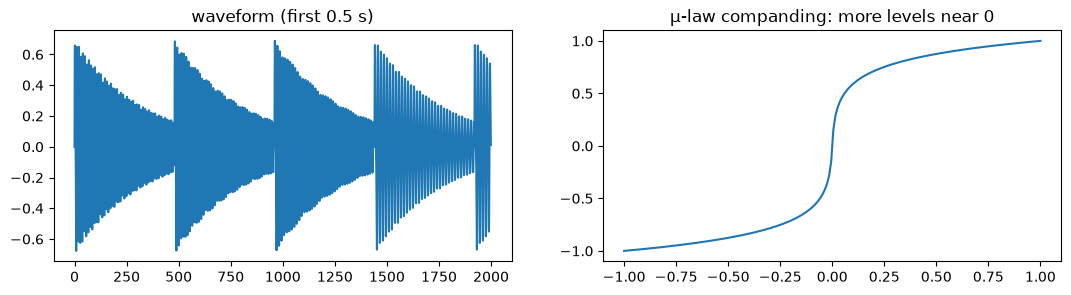

In [2]:
SR = 4000
scale = 220 * 2 ** (np.array([0, 2, 4, 5, 7, 9, 11, 12]) / 12)          # A3 major scale
def melody(n_notes=8, note_len=0.12, rng=np.random):
    out = []
    for _ in range(n_notes):
        f = rng.choice(scale); t = np.arange(int(SR * note_len)) / SR
        env = np.exp(-t * 12)
        out.append(env * (0.7 * np.sin(2 * np.pi * f * t) + 0.3 * np.sin(4 * np.pi * f * t)))
    return np.concatenate(out).astype(np.float32) * 0.8

def mu_law(x, mu=255):   return np.sign(x) * np.log1p(mu * np.abs(x)) / np.log1p(mu)
def mu_encode(x, mu=255): return ((mu_law(x, mu) + 1) / 2 * mu + 0.5).astype(np.int64)
def mu_decode(q, mu=255):
    y = 2 * (q.astype(np.float32) / mu) - 1
    return np.sign(y) * ((1 + mu) ** np.abs(y) - 1) / mu

rng = np.random.default_rng(0)
data = np.concatenate([melody(rng=rng) for _ in range(150)])
q = mu_encode(data)
print(f"{len(data) / SR:.0f} s of audio, {len(data):,} samples, 256 μ-law classes")
fig, axes = plt.subplots(1, 2, figsize=(13, 3))
axes[0].plot(data[:2000]); axes[0].set_title("waveform (first 0.5 s)")
xs = np.linspace(-1, 1, 200); axes[1].plot(xs, mu_law(xs)); axes[1].set_title("μ-law companding: more levels near 0")
plt.show()

In [3]:
class CausalConv(nn.Conv1d):
    def __init__(self, cin, cout, k, dilation=1):
        super().__init__(cin, cout, k, dilation=dilation); self.pad = (k - 1) * dilation
    def forward(self, x): return super().forward(F.pad(x, (self.pad, 0)))       # pad on the left only = causal

class ResidualBlock(nn.Module):
    def __init__(self, ch, dilation):
        super().__init__()
        self.filt, self.gate = CausalConv(ch, ch, 2, dilation), CausalConv(ch, ch, 2, dilation)
        self.res, self.skip = nn.Conv1d(ch, ch, 1), nn.Conv1d(ch, ch, 1)
    def forward(self, x):
        h = torch.tanh(self.filt(x)) * torch.sigmoid(self.gate(x))            # gated activation unit
        return x + self.res(h), self.skip(h)

class WaveNet(nn.Module):
    def __init__(self, ch=48, n_layers=10, stacks=2, Q=256):
        super().__init__()
        self.emb = nn.Embedding(Q, ch); self.inp = CausalConv(ch, ch, 2)
        self.blocks = nn.ModuleList([ResidualBlock(ch, 2 ** i) for _ in range(stacks) for i in range(n_layers)])
        self.out = nn.Sequential(nn.ReLU(), nn.Conv1d(ch, ch, 1), nn.ReLU(), nn.Conv1d(ch, Q, 1))
        self.receptive_field = 1 + stacks * (2 ** n_layers - 1) + 1
    def forward(self, x):                                                     # x: (B, T) ints -> (B, Q, T) logits
        h = self.inp(self.emb(x).transpose(1, 2)); skips = 0
        for b in self.blocks:
            h, s = b(h); skips = skips + s
        return self.out(skips)

model = WaveNet(n_layers=8, stacks=2).to(device)
print(f"receptive field: {model.receptive_field} samples = {model.receptive_field / SR * 1000:.0f} ms | parameters: {sum(p.numel() for p in model.parameters()) / 1e3:.0f}K")

receptive field: 512 samples = 128 ms | parameters: 256K


step    0  loss 5.550  (uniform guess = 5.55)


step  300  loss 0.006  (uniform guess = 5.55)


step  600  loss 0.005  (uniform guess = 5.55)


step  900  loss 0.005  (uniform guess = 5.55)


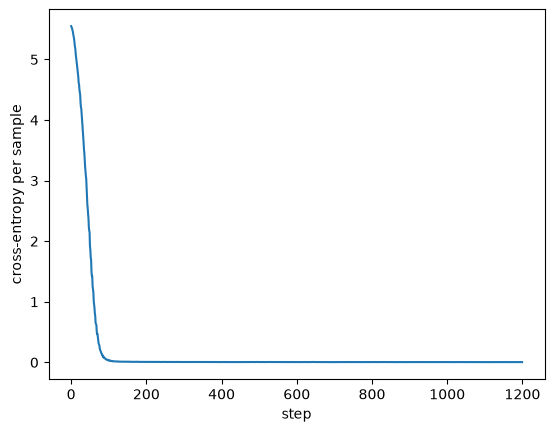

The loss gets very low because clean synthetic tones are highly predictable once a note has started; the hard part is the next note.


In [4]:
qt = torch.tensor(q, device=device)
opt = torch.optim.Adam(model.parameters(), lr=2e-3)
L = 1024; losses = []
for step in range(1200):
    ix = torch.randint(0, len(qt) - L - 1, (16,), device=device)
    x = torch.stack([qt[i:i + L] for i in ix]); y = torch.stack([qt[i + 1:i + L + 1] for i in ix])
    loss = F.cross_entropy(model(x)[:, :, model.receptive_field:], y[:, model.receptive_field:])
    opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
    if step % 300 == 0: print(f"step {step:4d}  loss {loss.item():.3f}  (uniform guess = {math.log(256):.2f})")
plt.plot(losses); plt.xlabel("step"); plt.ylabel("cross-entropy per sample"); plt.show()
print("The loss gets very low because clean synthetic tones are highly predictable once a note has started; the hard part is the next note.")

## Generating audio sample by sample
Start from a short real clip and let the model continue. Each new sample needs a forward pass over the receptive field. (Real-time WaveNet needed caching tricks, and later *Parallel WaveNet* distilled it into a feed-forward flow.)

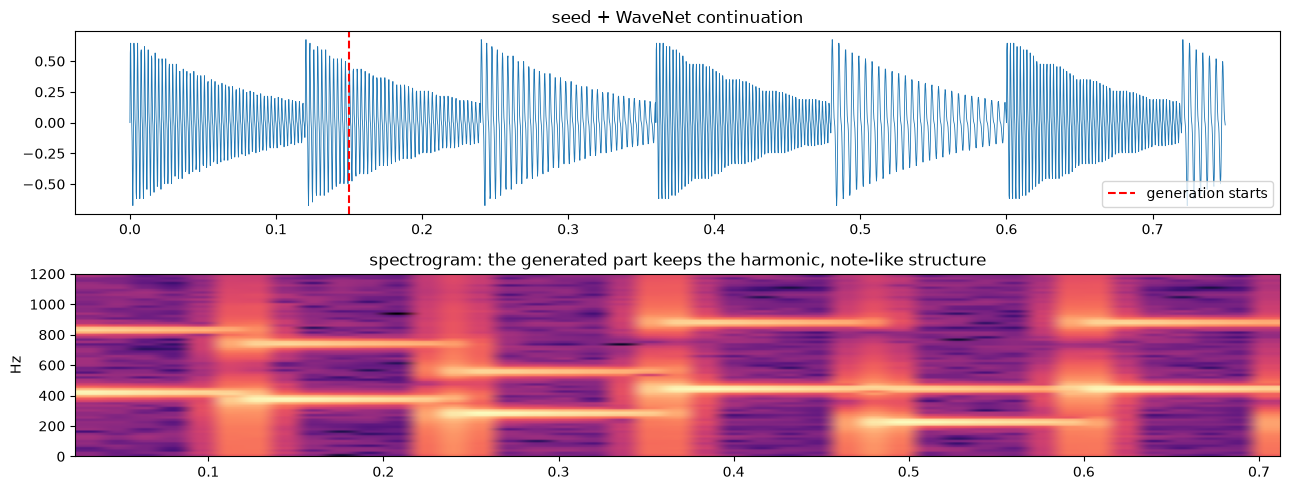

In [5]:
@torch.no_grad()
def generate(seed, n, temperature=0.9):
    model.eval(); seq = list(seed); R = model.receptive_field
    for _ in range(n):
        x = torch.tensor([seq[-R:]], device=device)
        p = F.softmax(model(x)[0, :, -1] / temperature, -1)
        seq.append(torch.multinomial(p, 1).item())
    return np.array(seq)

seed_len = 600
gen = generate(q[:seed_len], 2400)
audio = mu_decode(gen)
fig, axes = plt.subplots(2, 1, figsize=(13, 5))
axes[0].plot(np.arange(len(audio)) / SR, audio, lw=0.6); axes[0].axvline(seed_len / SR, c="r", ls="--", label="generation starts")
axes[0].legend(); axes[0].set_title("seed + WaveNet continuation")
axes[1].specgram(audio, Fs=SR, NFFT=256, noverlap=192, cmap="magma"); axes[1].set_ylim(0, 1200); axes[1].set_ylabel("Hz")
axes[1].set_title("spectrogram: the generated part keeps the harmonic, note-like structure")
plt.tight_layout(); plt.show()
try:
    from IPython.display import Audio, display
    display(Audio(audio, rate=SR))
except Exception as e:
    print("audio playback unavailable:", e)